Inainte sa trimiti notebook-ul:

* asigura-te ca totul se executa cum trebuie. Prima oara, **restarteaza kernel-ul** (in meniu, selecteaza Kernel$\rightarrow$Restart & Run all);

* nu lasa niciun mesaj la output (`disp`, `printf`, linii care nu sunt incheiate cu `;`) in functiile pe care le scrii decat daca ti se specifica explicit sa faci acest lucru! Orice abatere va fi **depunctata automat** de grader;

* citeste instructiunile de [aici](https://github.com/radusqrt/numerical-methods/blob/master/lab_instructions.md) cu atentie;

* asigura-te ca rezolvi toate celulele in care scrie `YOUR CODE HERE` sau `YOUR ANSWER HERE` si ca iti treci numele mai jos:

In [1]:
STUDENT_NAME = "Ionescu Andrei";

---

# Laborator 9: Interpolari
### Autor: Radu Stochitoiu

## Problema 1

Implementati funcția ```vandermonde(x, y)``` ce primește doi vectori linie, $x, y$, reprezentând coordonatele pe axele OX și OY ale unor puncte ce definesc suportul interpolării și returnează un vector coloană, $P$, ce reprezintă polinomul care trece prin toate punctele.

Primul element al lui $P$ reprezintă coeficientul celei mai mari puteri.

Ultimul element al lui $P$ reprezintă coeficientul celei mai mici puteri ($x^0$).

In [2]:
function [P] = vandermonde(x, y)
    n = length(x);
    % Generam A cu puterile lui x_i pe fiecare coloana i
    A = [ones(n, 1), (ones(n-1, 1) * x)'] .^ [0:n-1];
    y = y';
    
    % Rezolvam A * P = y
    P = flip(linsolve(A, y));
endfunction

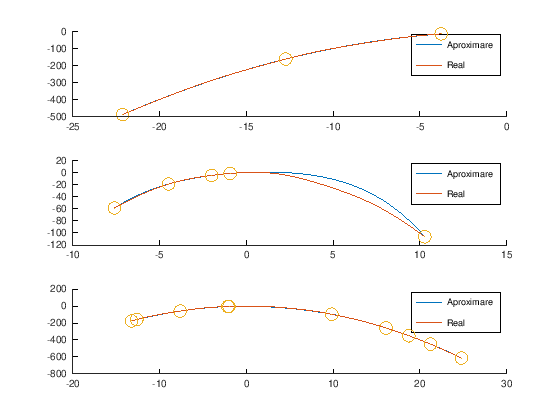

In [3]:
function [y] = f(x)
    y = sin(x) - x.^2;
endfunction

% Test 1
x = sort((rand(1, 3) - 0.5) * 50);
y = f(x);
P = vandermonde(x, y);

subplot(3, 1, 1);
hold
xx = linspace(min(x), max(x));
yy = polyval(P, xx);
plot(xx, yy)
plot(xx, f(xx))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(polyval(P, x(i)) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

% Test 2
x = sort((rand(1, 5) - 0.5) * 50);
y = f(x);
P = vandermonde(x, y);

subplot(3, 1, 2);
hold
xx = linspace(min(x), max(x));
yy = polyval(P, xx);
plot(xx, yy)
plot(xx, f(xx))
hold on
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(polyval(P, x(i)) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

% Test 3
x = sort((rand(1, 10) - 0.5) * 50);
y = f(x);
P = vandermonde(x, y);

subplot(3, 1, 3);
hold
xx = linspace(min(x), max(x));
yy = polyval(P, xx);
plot(xx, yy)
plot(xx, f(xx))
hold on
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(polyval(P, x(i)) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

## Problema 2

Implementati funcția ```lagrange(x, y, xx)``` ce primește doi vectori linie, $x, y$, reprezentând coordonatele pe axele OX și OY ale unor puncte ce definesc suportul interpolării și un vector linie $xx$ pentru care vrem să găsim valorile aproximate și returnează un vector linie, $yy$, ce reprezintă valorile interpolării Lagrange cu suportul $x, y$ prin toate punctele $xx$.

In [4]:
function [P] = newton(x, y)
    n = length(x);
    P = [];

    for i = 1:n-1
        P = [newton_helper(x, y, 0, i), P];
    endfor
endfunction

% Functie care calculeaza recursiv coeficientul f[x_start, ..., x_stop]
function [b] = newton_helper(x, y, start, stop)
    if (start == stop)
        b = y(start);
    else
        b = (newton_helper(x, y, start+1, stop) - newton_helper(x, y, ...
            start, stop-1)) ./ (x(stop) - x(start));
    endif
endfunction

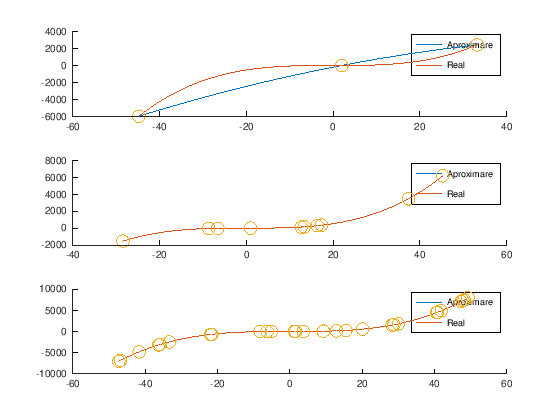

In [5]:
function [y] = f(x)
    y = x.^3 / 15 - 3;
endfunction

% Test 1
x = sort((rand(1, 3) - 0.5) * 100);
y = f(x);
xx = linspace(min(x), max(x));
yy = lagrange(x, y, xx);
yy_test = lagrange(x, y, x);

subplot(3, 1, 1);
hold;
plot(xx, yy)
plot(xx, f(xx))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(yy_test(i) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

% Test 2
x = sort((rand(1, 10) - 0.5) * 100);
y = f(x);
xx = linspace(min(x), max(x));
yy = lagrange(x, y, xx);
yy_test = lagrange(x, y, x);

subplot(3, 1, 2);
hold
plot(xx, yy)
plot(xx, f(xx))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(yy_test(i) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

% Test 3
x = sort((rand(1, 30) - 0.5) * 100);
y = f(x);
xx = linspace(min(x), max(x));
yy = lagrange(x, y, xx);
yy_test = lagrange(x, y, x);

subplot(3, 1, 3);
hold
plot(xx, yy)
plot(xx, f(xx))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(yy_test(i) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

## Problema 3

Implementati funcția ```newton(x, y)``` ce primește doi vectori linie, $x, y$, reprezentând coordonatele pe axele OX și OY ale unor puncte ce definesc suportul interpolării și returnează un vector linie, $P$, ce reprezintă coeficienții interpolării prin diferențe divizate ($b_0, b_1, ...$).

Primul element al lui $P$ reprezintă coeficientul celei mai mari puteri.

Ultimul element al lui $P$ reprezintă coeficientul celei mai mici puteri.

In [12]:
function [P] = newton(x, y)
    n = length(x);
    P = [];

    for i = 1:n
        P = [newton_helper(x, y, 1, i), P];
    endfor
endfunction

% Functie care calculeaza recursiv coeficientul f[x_start, ..., x_stop]
function [b] = newton_helper(x, y, start, stop)
    if (start == stop)
        b = y(start);
    else
        b = (newton_helper(x, y, start+1, stop) - newton_helper(x, y, ...
            start, stop-1)) ./ (x(stop) - x(start));
    endif
endfunction

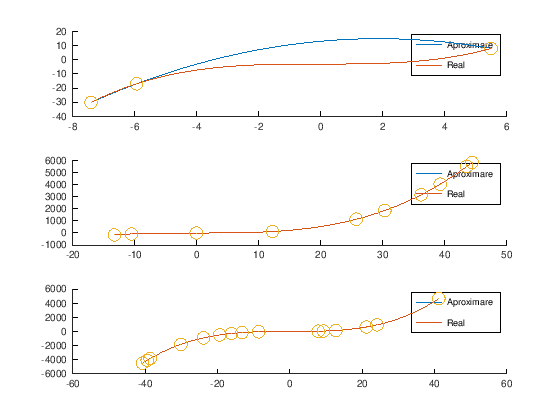

In [13]:
function [y] = newton_eval(P, xx, x)
    y = 0;
    p = 1;
    for i = 1:length(P)
        y += p .* P(length(P) - i + 1);
        p = p .* (x - xx(i));
    endfor
endfunction

function [y] = f(x)
    y = x.^3 / 15 - 3;
endfunction

% Test 1
x = sort((rand(1, 3) - 0.5) * 100);
y = f(x);
xx = linspace(min(x), max(x));
P = newton(x, y);
yy = newton_eval(P, x, xx);
yy_test = newton_eval(P, x, x);

subplot(3, 1, 1);
hold;
plot(xx, yy)
plot(xx, f(xx))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(yy_test(i) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

% Test 2
x = sort((rand(1, 10) - 0.5) * 100);
y = f(x);
xx = linspace(min(x), max(x));
P = newton(x, y);
yy = newton_eval(P, x, xx);
yy_test = newton_eval(P, x, x);

subplot(3, 1, 2);
hold;
plot(xx, yy)
plot(xx, f(xx))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(yy_test(i) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

% Test 3
x = sort((rand(1, 15) - 0.5) * 100);
y = f(x);
xx = linspace(min(x), max(x));
P = newton(x, y);
yy = newton_eval(P, x, xx);
yy_test = newton_eval(P, x, x);

subplot(3, 1, 3);
hold;
plot(xx, yy)
plot(xx, f(xx))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(yy_test(i) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

## Problema 4

Implementati funcția ```neville(x, y, xx)``` ce primește doi vectori linie, $x, y$, reprezentând coordonatele pe axele OX și OY ale unor puncte ce definesc suportul interpolării și un vector linie $xx$ pentru care vrem să găsim valorile aproximate și returnează un vector linie, $yy$, ce reprezintă valorile interpolării Neville cu suportul $x, y$ prin toate punctele $xx$.

In [8]:
    function [yy] = neville(x, y, xx)
        n = length(y);
        % Pentru a paraleliza calculul in toate punctele xx
        y = ones(length(xx), 1) * y;
        
        % i etape de combinari de P (dupa un pas i, vom avea polinoame de gard i)
        for i = 1:n-1
            % Combinarile de 2 P intr-un P de grad mai mare
            [~, m] = size(y);
            for j = 1:m-1
                % Fiecare linie k contine P de grad curent, i-1, in punctul xx(k)
                y(:, j) = ((xx' - x(j+i)) .* y(:, j) - (xx' - x(j)) .* y(:, j+1)) ./ (x(j) - x(j+i));
            endfor
            y = y(:, 1:(end-1));
        endfor
        
        yy = y';
    endfunction

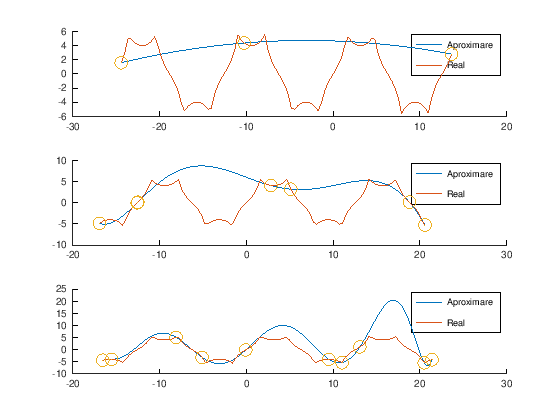

In [9]:
function [y] = f(x)
    y = 8 * sin(x / 2) ./ (abs(cos(x)) + 1);
endfunction

% Test 1
x = sort((rand(1, 3) - 0.5) * 50);
y = f(x);
xx = linspace(min(x), max(x));
yy = neville(x, y, xx);
yy_test = neville(x, y, x);

subplot(3, 1, 1);
hold;
plot(xx, yy)
plot(xx, f(xx))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(yy_test(i) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

% Test 2
x = sort((rand(1, 7) - 0.5) * 50);
y = f(x);
xx = linspace(min(x), max(x));
yy = neville(x, y, xx);
yy_test = neville(x, y, x);

subplot(3, 1, 2);
hold;
plot(xx, yy)
plot(xx, f(xx))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(yy_test(i) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

% Test 3
x = sort((rand(1, 10) - 0.5) * 50);
y = f(x);
xx = linspace(min(x), max(x));
yy = neville(x, y, xx);
yy_test = neville(x, y, x);

subplot(3, 1, 3);
hold;
plot(xx, yy)
plot(xx, f(xx))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(yy_test(i) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

## Problema 5

Implementati funcția ```spline_c2_natural(x, y)``` ce primește doi vectori linie, $x, y$, reprezentând coordonatele pe axele OX și OY ale unor puncte ce definesc suportul interpolării și returnează o matrice $S$ ce are pe linia i coeficienții $a_{i-1}, b_{i-1}, c_{i-1}, d_{i-1}$.

In [10]:
function [S] = spline_c2_natural(x, y)
    n = length(x);
    A = [];
    b = [];
    
    % Generam sistemul de ecuatii
    % Pas 1:
    % S_i(x_i) = y_i
    for i = 1:n
        A = [A; [zeros(1, (i-1)*4), 1, zeros(1, (n-i)*4+3)]];
        b = [b; y(i)];
    endfor
    % S_{n-1}(x_n) = y_n
    A = [A; [zeros(1, (n-1)*4), ones(1, 4)]];
    b = [b; y(n)];
    
    % Pas 2:
    % S_i(x_{i+1}) = S_{i+1}(x_{i+1})
    for i = 1:n-1
        aux = x(i+1) - x(i);
        A = [A; [zeros(1, (i-1)*4), 1, aux, aux^2, aux^3, -1,...
            zeros(1, (n-i-1)*4+3)]];
        b = [b; 0];
    endfor
    
    % Pas 3:
    % S_i'(x_{i+1}) = S_{i+1}'(x_{i+1})
    for i = 1:n-1
        aux = x(i+1) - x(i);
        A = [A; [zeros(1, (i-1)*4), 0, 1, 2*aux, 3*aux^2, 0, -1,...
            zeros(1, (n-i-1)*4+2)]];
        b = [b; 0];
    endfor
    
    % Pas 4:
    % S_i''(x_{i+1}) = S_{i+1}''(x_{i+1})
    for i = 1:n-1
        aux = x(i+1) - x(i);
        A = [A; [zeros(1, (i-1)*4), 0, 0, 2, 6*aux, 0, 0, -2,...
            zeros(1, (n-i-1)*4+1)]];
        b = [b; 0];
    endfor
    
    % Pas 5:
    % S_1''(x_1) = S_{n-1}''(x_n) = 0;
    A = [A; [0, 0, 1, 0, zeros(1, (n-1)*4)]];
    A = [A; [zeros(1, (n-1)*4), 0, 0, 2, 6*(x(n) - x(n-1))]];
    b = [b; 0; 0];
    
    S = linsolve(A, b);
    S = reshape(S, 4, n)';
endfunction

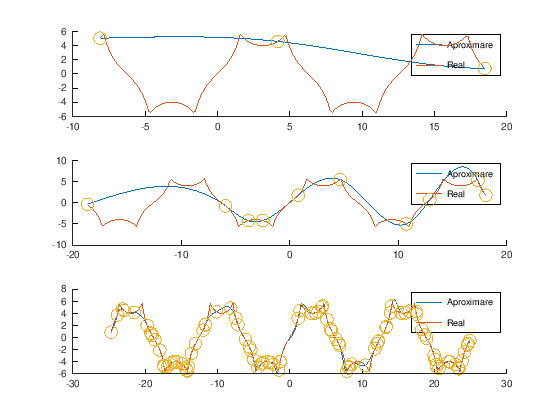

In [11]:
function [XX, YY] = spline_eval(S, x, y)
    XX = [];
    YY = [];
    n = length(x) - 1;
    for i = 1:n
        s = S(i, :);
        xx = linspace(x(i), x(i + 1));
        yy = s(1);
        yy += s(2) * (xx - repmat(x(i), 1, 100));
        yy += s(3) * (xx - repmat(x(i), 1, 100)) .^ 2;
        yy += s(4) * (xx - repmat(x(i), 1, 100)) .^ 3;
        XX = [XX, xx];
        YY = [YY, yy];
    endfor
endfunction

function [y] = f(x)
    y = 8 * sin(x / 2) ./ (abs(cos(x)) + 1);
endfunction

% Test 1
x = sort((rand(1, 3) - 0.5) * 50);
y = f(x);

xx = linspace(min(x), max(x));
S = spline_c2_natural(x, y);
[XX, YY] = spline_eval(S, x, y);

subplot(3, 1, 1);
hold;
plot(XX, YY)
plot(XX, f(XX))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x) - 1
    assert(norm(YY(100 * (i - 1) + 1) - y(i)) < 1e-4);
endfor
assert(norm(YY(end) - y(end)) < 1e-4);
legend("Aproximare", "Real")

% Test 2
x = sort((rand(1, 10) - 0.5) * 50);
y = f(x);

xx = linspace(min(x), max(x));
S = spline_c2_natural(x, y);
[XX, YY] = spline_eval(S, x, y);

subplot(3, 1, 2);
hold;
plot(XX, YY)
plot(XX, f(XX))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x) - 1
    assert(norm(YY(100 * (i - 1) + 1) - y(i)) < 1e-4);
endfor
assert(norm(YY(end) - y(end)) < 1e-4);
legend("Aproximare", "Real")

% Test 3
x = sort((rand(1, 100) - 0.5) * 50);
y = f(x);

xx = linspace(min(x), max(x));
S = spline_c2_natural(x, y);
[XX, YY] = spline_eval(S, x, y);

subplot(3, 1, 3);
hold;
plot(XX, YY)
plot(XX, f(XX))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x) - 1
    assert(norm(YY(100 * (i - 1) + 1) - y(i)) < 1e-4);
endfor
assert(norm(YY(end) - y(end)) < 1e-4);
legend("Aproximare", "Real")